[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/danpele/MFM/blob/main/notebooks/RO/capitol6_notebook_seminar.ipynb)

# Modelarea piețelor financiare — Seminarul 6: Volatilitate multivariată și dependență

*Notebook de seminar. Daniel Traian Pele, Antoaneta Amza, Academia de Studii Economice din București.*

- Problemele **[Rezolvat]** conțin rezolvarea completă; problemele **[Propus]** le rezolvați dumneavoastră.
- Partea A: derivări (A1–A6); Partea B: estimare și inferență (B1–B6); Partea C: critica unui răspuns Artificial Intelligence (AI) (C1), întrebare deschisă (C2) și temă de proiect (C3).
- Seminarul are loc înaintea cursului 6; slide-urile încep cu o scurtă secțiune introductivă (copule, dependența în cozi, Dynamic Conditional Correlation (DCC), Forbes–Rigobon).
- **La seminar**, în această ordine: A1, A2, A3, B1, B2, B3 (cerințele 1–2), C1. **După curs**: B3, cerințele 3–4 (celula de bootstrap din B3), B4 și C2; celelalte secțiuni sînt extensii opționale.

> Rezolvările se discută la seminar.

In [1]:
import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import networkx as nx
from scipy import stats, optimize, integrate
from scipy.signal import lfilter
from scipy.special import gammaln
try:
    from arch import arch_model
except ImportError:                      # Colab: pip install arch
    import subprocess, sys
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'arch'], check=True)
    from arch import arch_model
import warnings
warnings.filterwarnings('ignore')

Matplotlib is building the font cache; this may take a moment.


## Stil și funcții ajutătoare

In [2]:
# Chart style: transparent background, legend below the plot
plt.rcParams['figure.facecolor'] = 'none'
plt.rcParams['axes.facecolor'] = 'none'
plt.rcParams['savefig.facecolor'] = 'none'
plt.rcParams['savefig.transparent'] = True
plt.rcParams['axes.grid'] = False
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['Helvetica', 'Arial', 'DejaVu Sans']
plt.rcParams['font.size'] = 9
plt.rcParams['axes.labelsize'] = 10
plt.rcParams['axes.titlesize'] = 11
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False
plt.rcParams['axes.linewidth'] = 0.6
plt.rcParams['lines.linewidth'] = 1.1
plt.rcParams['legend.facecolor'] = 'none'
plt.rcParams['legend.framealpha'] = 0
plt.rcParams['legend.fontsize'] = 8

# Colours
MainBlue = '#1A3A6E'
IDAred   = '#CD0000'
Forest   = '#2E7D32'
Amber    = '#B5853F'
Orange   = '#E67E22'
Purple   = '#8E44AD'
Crimson  = '#DC3545'
Navy     = '#1F2A44'   # reference lines (no grey in charts)
BandBlue = '#C5D2E8'   # light MainBlue tint for confidence / reference bands
Gray, LightGray = Navy, BandBlue   # legacy names kept for importing scripts
FAM_COL = {'gaussian': MainBlue, 't': IDAred, 'clayton': Forest, 'gumbel': Amber, 'frank': Purple}

SIDE = (5.6, 3.5)   # size of the charts placed next to text

SEED = 42
NUM = {}
TABLE_DIR = '.'


def save_fig(name):
    """Save the figure as transparent PDF and PNG in the current folder."""
    plt.savefig(f'{name}.pdf', bbox_inches='tight', transparent=True)
    plt.savefig(f'{name}.png', bbox_inches='tight', transparent=True, dpi=180)
    plt.show()
    plt.close()
    print(f"   saved {name}")


def legend_outside_bottom(ax, ncol=2, y=-0.22):
    """Place the legend outside the plot, bottom centre."""
    ax.legend(loc='upper center', bbox_to_anchor=(0.5, y), ncol=ncol, frameon=False)


def shade_crises(ax, alpha=0.5):
    for a, b in (('2008-09-15', '2009-03-31'), ('2020-02-20', '2020-04-30'), ('2022-01-03', '2022-10-31')):
        ax.axvspan(pd.Timestamp(a), pd.Timestamp(b), color=BandBlue, alpha=alpha, lw=0)


import tempfile
SAVE_OUT = globals().get('SAVE_TO_DRIVE', False)   # se seteaza in celula Drive de la inceput
OUT_DIR = globals().get('OUT_DIR', '.')
TABLE_DIR = OUT_DIR if SAVE_OUT else tempfile.gettempdir()   # tabele: folderul din Drive sau un folder temporar


def save_fig(name):
    """Salveaza figura in OUT_DIR (PDF si PNG) cand SAVE_TO_DRIVE este activ, apoi o afiseaza."""
    if SAVE_OUT:
        plt.savefig(os.path.join(OUT_DIR, f'{name}.pdf'), bbox_inches='tight', transparent=True)
        plt.savefig(os.path.join(OUT_DIR, f'{name}.png'), bbox_inches='tight', transparent=True, dpi=180)
    plt.show()
    plt.close()

## Date

- Prețuri zilnice pînă la 18 septembrie 2026: SPY, TLT, S&P 500, Euro Stoxx 50, Bucharest Exchange Trading (index) (BET), Bitcoin și șase bănci.
- ETF-uri și acțiuni: închideri ajustate; indici și Bitcoin: închideri.
- Analizele comune: prețurile se aliniază întîi pe zilele comune de tranzacționare, apoi se calculează randamentele logaritmice.
- Randamentele săptămînale folosesc ultima închidere comună a fiecărei săptămîni (vineri).

In [3]:
import os
import numpy as np
import pandas as pd

REPO_RAW = 'https://raw.githubusercontent.com/danpele/MFM/main/data/market/'
MARKET_DIR = next((os.path.join(d, 'data', 'market') for d in ('.', '..', '../..', '../../..')
                   if os.path.isdir(os.path.join(d, 'data', 'market'))), '')
END = '2026-09-18'

# name -> (symbol, price field, label, start date)
ASSETS = {
    'spy':   ('SPY.US',        'adjusted_close', 'SPY (S&P 500 ETF)',          '2002-07-30'),
    'tlt':   ('TLT.US',        'adjusted_close', 'TLT (20+y Treasury ETF)',    '2002-07-30'),
    'ief':   ('IEF.US',        'adjusted_close', 'IEF (7-10y Treasury ETF)',   '2002-07-30'),
    'sp500': ('GSPC.INDX',     'close',          'S&P 500',                    '2000-01-01'),
    'stoxx': ('STOXX50E.INDX', 'close',          'Euro Stoxx 50',              '2000-01-01'),
    'bet':   ('BET',           'close',          'BET (Romania)',              '2000-01-01'),
    'bettr': ('BETTR.INDX',    'close',          'BET-TR (Romania)',           '2014-09-23'),
    'btc':   ('BTC-USD.CC',    'close',          'Bitcoin',                    '2014-09-17'),
    'vix':   ('VIX.INDX',      'close',          'VIX',                        '2000-01-01'),
    'jpm':   ('JPM.US',        'adjusted_close', 'JPMorgan Chase',             '2010-01-01'),
    'bac':   ('BAC.US',        'adjusted_close', 'Bank of America',            '2010-01-01'),
    'dbk':   ('DBK.XETRA',     'adjusted_close', 'Deutsche Bank',              '2010-01-01'),
    'bnp':   ('BNP.PA',        'adjusted_close', 'BNP Paribas',                '2010-01-01'),
    'tlv':   ('TLV.RO',        'adjusted_close', 'Banca Transilvania',         '2010-01-01'),
    'brd':   ('BRD.RO',        'adjusted_close', 'BRD-Groupe Societe Generale', '2010-01-01'),
}
# US-listed ETFs for the COVOL case study (Engle and Campos-Martins, 2023, Section 9)
COVOL_ETFS = ['XLB', 'XLC', 'XLE', 'XLF', 'XLI', 'XLK', 'XLP', 'XLRE', 'XLU', 'XLV', 'XLY',
              'IWF', 'IWD', 'IWM', 'EFA', 'EEM', 'GLD', 'TLT', 'LQD', 'USO']
for _e in COVOL_ETFS:
    ASSETS['etf_' + _e.lower()] = (f'{_e}.US', 'adjusted_close', _e, '1999-12-31')
LABELS = {k: v[2] for k, v in ASSETS.items()}
SHORT = {'spy': 'SPY', 'tlt': 'TLT', 'ief': 'IEF', 'sp500': 'S&P 500', 'stoxx': 'Euro Stoxx 50', 'bet': 'BET',
         'bettr': 'BET-TR', 'btc': 'Bitcoin', 'vix': 'VIX', 'jpm': 'JPM', 'bac': 'BAC', 'dbk': 'DBK', 'bnp': 'BNP',
         'tlv': 'TLV', 'brd': 'BRD'}
BANKS = ['jpm', 'bac', 'dbk', 'bnp', 'tlv', 'brd']


def read_market(symbol):
    """Daily series of one asset from the course data."""
    fname = f'{symbol}.csv'
    path = os.path.join(MARKET_DIR, fname)
    src = path if os.path.exists(path) else REPO_RAW + fname
    return pd.read_csv(src, index_col='date', parse_dates=True).sort_index()


def load_price(name, start=None, end=END):
    """Daily price, cleaned with the conventions of the chapter."""
    symbol, col, _, start0 = ASSETS[name]
    d = read_market(symbol).loc[start or start0:end]
    d = d[d[col] > 0].dropna(subset=[col])
    s = d[col]
    if name != 'btc':
        keep = s.index.dayofweek < 5                                   # no weekend quotes
        vol = d['volume'].fillna(0) if 'volume' in d else pd.Series(0.0, index=d.index)
        keep &= ~((s.diff() == 0) & (vol <= 0)).values                # holidays: unchanged price AND zero volume
        s = s[keep]                                                    # (trading days with volume and an unchanged price stay)
    return s.rename(name)


def joint_prices(names, start=None, end=END):
    """Prices of the assets on their common trading days."""
    return pd.concat([load_price(n, start, end) for n in names], axis=1, join='inner').dropna()


def joint_returns(names, start=None, end=END):
    """Daily log returns, computed AFTER aligning the prices on common days."""
    return np.log(joint_prices(names, start, end)).diff().dropna()


def weekly_returns(names, start=None, end=END):
    """Weekly log returns: the last common price of each week (Friday), then differences."""
    p = joint_prices(names, start, end)
    return np.log(p.resample('W-FRI').last()).diff().dropna()

## Instrumente pentru dependență

- Covarianțe Exponentially Weighted Moving Average (EWMA) și pe ferestre mobile, intervale Fisher.
- Generalised AutoRegressive Conditional Heteroskedasticity (GARCH)(1,1) univariat și DCC(1,1) în doi pași (Engle, 2002).
- Corecția Forbes–Rigobon, corelații de depășire.
- Cinci copule bivariate: densitate, repartiția condiționată $h(v\mid u)$, simulare, legătura cu $\tau$, dependența în cozi, verosimilitate maximă canonică și testul de adecvare Rosenblatt cu bootstrap parametric.

In [4]:
import numpy as np
import pandas as pd
from scipy import stats, optimize, integrate
from scipy.signal import lfilter
from scipy.special import gammaln
from arch import arch_model
try:
    from numba import njit
except ImportError:                      # without numba the same functions run as plain Python (slower)
    def njit(*args, **kwargs):
        return args[0] if (len(args) == 1 and callable(args[0])) else (lambda f: f)


# =============================================================================
# EWMA and rolling window
# =============================================================================
def ewma_cov(R, lam=0.94, init=100):
    """Sigma_t = lam*Sigma_{t-1} + (1-lam) r_{t-1} r_{t-1}'  (forecast for day t, without r_t).
    The first init observations only initialise the recursion: Sigma_init = their covariance; NaN before init."""
    X = np.asarray(R, dtype=float)
    T, N = X.shape
    S = np.full((T, N, N), np.nan)
    S[init] = np.cov(X[:init].T)
    for t in range(init + 1, T):
        S[t] = lam * S[t - 1] + (1 - lam) * np.outer(X[t - 1], X[t - 1])
    return S


def ewma_corr(R, lam=0.94, i=0, j=1):
    S = ewma_cov(R, lam)
    return pd.Series(S[:, i, j] / np.sqrt(S[:, i, i] * S[:, j, j]), index=R.index)


def rolling_corr(R, window, a=None, b=None):
    a, b = a or R.columns[0], b or R.columns[1]
    return R[a].rolling(window).corr(R[b])


def fisher_ci(rho, n, level=0.95):
    """Confidence interval for a correlation by the Fisher z transformation (i.i.d. data)."""
    z, se = np.arctanh(rho), 1 / np.sqrt(n - 3)
    q = stats.norm.ppf(0.5 + level / 2)
    return np.tanh(z - q * se), np.tanh(z + q * se)


# =============================================================================
# Univariate GARCH(1,1) -- the first step of DCC
# =============================================================================
def garch_filter(r, dist='normal'):
    """GARCH(1,1) with constant mean on returns in percent (QML).
    Returns the parameters, the conditional volatility (%) and the standardised residuals."""
    res = arch_model(100 * r, mean='Constant', vol='GARCH', p=1, q=1, dist=dist).fit(disp='off')
    z = (res.resid / res.conditional_volatility).rename(r.name)
    return res.params, res.conditional_volatility.rename(r.name), z, res.loglikelihood


def garch_all(R, dist='normal'):
    out = {c: garch_filter(R[c], dist) for c in R.columns}
    Z = pd.concat([out[c][2] for c in R.columns], axis=1)
    V = pd.concat([out[c][1] for c in R.columns], axis=1)
    P = pd.DataFrame({c: out[c][0] for c in R.columns})
    ll = sum(out[c][3] for c in R.columns)
    return P, V, Z, ll


# =============================================================================
# DCC (Engle, 2002): Q_t = (1-a-b) Qbar + a z_{t-1} z_{t-1}' + b Q_{t-1}
# =============================================================================
def dcc_path(Z, a, b, Qbar=None):
    """Correlation matrices R_t (T x N x N). Each element of Q_t follows a linear recursion,
    computed in vectorised form with lfilter."""
    X = np.asarray(Z, dtype=float)
    T, N = X.shape
    Qbar = np.cov(X.T, bias=True) if Qbar is None else Qbar
    P = np.einsum('ti,tj->tij', X, X)                  # z_t z_t'
    drive = np.empty_like(P)
    drive[0] = Qbar
    drive[1:] = (1 - a - b) * Qbar + a * P[:-1]         # input at time t: uses z_{t-1}
    Q = lfilter([1.0], [1.0, -b], drive.reshape(T, -1), axis=0).reshape(T, N, N)
    Q[0] = Qbar
    d = np.sqrt(np.einsum('tii->ti', Q))
    return Q / (d[:, :, None] * d[:, None, :])


@njit(cache=True)
def dcc2_corr_loglik(x, y, a, b, q11b, q22b, q12b):
    """Bivariate case of dcc_corr_loglik, written as a single loop (same recursion as dcc_path)."""
    q11, q22, q12 = q11b, q22b, q12b
    c = 1.0 - a - b
    ll = 0.0
    for t in range(len(x)):
        r = q12 / np.sqrt(q11 * q22)
        d = 1.0 - r * r
        ll += -0.5 * (np.log(d) + (x[t] * x[t] + y[t] * y[t] - 2.0 * r * x[t] * y[t]) / d - x[t] * x[t] - y[t] * y[t])
        q11 = c * q11b + a * x[t] * x[t] + b * q11
        q22 = c * q22b + a * y[t] * y[t] + b * q22
        q12 = c * q12b + a * x[t] * y[t] + b * q12
    return ll


def dcc_corr_loglik(Z, a, b, Qbar=None):
    """Correlation part of the log-likelihood: -1/2 sum(log|R_t| + z'R_t^{-1}z - z'z)."""
    X = np.asarray(Z, dtype=float)
    if X.shape[1] == 2:
        Q = np.cov(X.T, bias=True) if Qbar is None else Qbar
        return dcc2_corr_loglik(np.ascontiguousarray(X[:, 0]), np.ascontiguousarray(X[:, 1]), float(a), float(b),
                                Q[0, 0], Q[1, 1], Q[0, 1])
    R = dcc_path(X, a, b, Qbar)
    sign, logdet = np.linalg.slogdet(R)
    quad = np.einsum('ti,tij,tj->t', X, np.linalg.inv(R), X)
    return -0.5 * np.sum(logdet + quad - np.sum(X ** 2, axis=1))


def ccc_loglik(Z):
    """CCC (Bollerslev, 1990): constant correlation = DCC with a = b = 0."""
    return dcc_corr_loglik(Z, 0.0, 0.0)


def _num_hessian(f, x, h=1e-4):
    k = len(x)
    H = np.zeros((k, k))
    for i in range(k):
        for j in range(k):
            e_i, e_j = np.eye(k)[i] * h, np.eye(k)[j] * h
            H[i, j] = (f(x + e_i + e_j) - f(x + e_i - e_j) - f(x - e_i + e_j) + f(x - e_i - e_j)) / (4 * h * h)
    return H


def dcc_fit(Z, start=(0.03, 0.95)):
    """Step 2 of DCC: (a, b) by maximum likelihood, with Qbar fixed at the sample covariance of standardised residuals
    (correlation targeting). The standard errors come from the step-2 Hessian (they ignore the step-1 error)."""
    X = np.asarray(Z, dtype=float)
    Qbar = np.cov(X.T, bias=True)

    def nll(p):
        a, b = p
        if a < 0 or b < 0 or a + b >= 0.9999:
            return 1e10
        return -dcc_corr_loglik(X, a, b, Qbar)

    best = None
    for s in (start, (0.01, 0.98), (0.05, 0.90), (0.10, 0.80)):
        r = optimize.minimize(nll, s, method='Nelder-Mead', options=dict(xatol=1e-7, fatol=1e-7, maxiter=4000))
        if best is None or r.fun < best.fun:
            best = r
    a, b = best.x
    try:
        H = _num_hessian(lambda p: -nll(p), best.x)
        se = np.sqrt(np.diag(np.linalg.inv(-H)))
    except Exception:
        se = np.array([np.nan, np.nan])
    return dict(a=a, b=b, se_a=se[0], se_b=se[1], loglik=-best.fun, Qbar=Qbar,
                R=dcc_path(X, a, b, Qbar), ccc_loglik=ccc_loglik(X))


# =============================================================================
# Forbes-Rigobon (2002)
# =============================================================================
def fr_adjust(rho_c, delta):
    """Crisis correlation adjusted for the rise in the variance of the source market:
    rho* = rho_c / sqrt(1 + delta (1 - rho_c^2)), delta = Var_crisis/Var_calm - 1."""
    return rho_c / np.sqrt(1 + delta * (1 - rho_c ** 2))


def fisher_z_test(rho1, n1, rho0, n0):
    """H0: rho1 <= rho0 (one-sided test, independent samples)."""
    z = (np.arctanh(rho1) - np.arctanh(rho0)) / np.sqrt(1 / (n1 - 3) + 1 / (n0 - 3))
    return z, 1 - stats.norm.cdf(z)


def exceedance_corr(x, y, qs):
    """Exceedance correlation (Longin-Solnik, 2001): corr(x, y | x<q_x, y<q_y) for lower tails and
    corr(x, y | x>q_x, y>q_y) for upper tails, at the same marginal quantiles."""
    out = []
    for q in qs:
        lo = (x <= np.quantile(x, q)) & (y <= np.quantile(y, q))
        hi = (x >= np.quantile(x, 1 - q)) & (y >= np.quantile(y, 1 - q))
        out.append((q, np.corrcoef(x[lo], y[lo])[0, 1] if lo.sum() > 5 else np.nan, lo.sum(),
                    np.corrcoef(x[hi], y[hi])[0, 1] if hi.sum() > 5 else np.nan, hi.sum()))
    return pd.DataFrame(out, columns=['q', 'rho_low', 'n_low', 'rho_high', 'n_high']).set_index('q')


# =============================================================================
# Bivariate copulas
# =============================================================================
FAMILIES = ['gaussian', 't', 'clayton', 'gumbel', 'frank']
FAM_LABEL = {'gaussian': 'Gaussian', 't': 'Student t', 'clayton': 'Clayton', 'gumbel': 'Gumbel', 'frank': 'Frank'}
EPS = 1e-10


def pseudo_obs(X):
    """Pseudo-observations: rank / (n + 1), column by column."""
    X = np.asarray(X, dtype=float)
    return np.column_stack([stats.rankdata(X[:, k]) / (len(X) + 1) for k in range(X.shape[1])])


def kendall_tau(u, v):
    return stats.kendalltau(u, v)[0]


def spearman_rho(u, v):
    return stats.spearmanr(u, v)[0]


def _debye1(x):
    if abs(x) < 1e-8:
        return 1.0
    val = integrate.quad(lambda t: t / np.expm1(t), 0, abs(x))[0] / abs(x)
    return val if x > 0 else val + abs(x) / 2


def tau_of(fam, theta):
    """Kendall's tau implied by the copula parameter."""
    if fam in ('gaussian', 't'):
        return 2 / np.pi * np.arcsin(theta[0] if np.ndim(theta) else theta)
    th = float(np.atleast_1d(theta)[0])
    if fam == 'clayton':
        return th / (th + 2)
    if fam == 'gumbel':
        return 1 - 1 / th
    if fam == 'frank':
        return 1 - 4 / th * (1 - _debye1(th))


def theta_from_tau(fam, tau):
    """Inversion of the tau <-> parameter relation (method of moments on Kendall's tau)."""
    if fam in ('gaussian', 't'):
        return np.sin(np.pi * tau / 2)
    if fam == 'clayton':
        return 2 * tau / (1 - tau)
    if fam == 'gumbel':
        return 1 / (1 - tau)
    if fam == 'frank':
        return optimize.brentq(lambda th: tau_of('frank', th) - tau, 1e-6 if tau > 0 else -60, 60 if tau > 0 else -1e-6)


def tail_dep(fam, par):
    """(lambda_L, lambda_U) for the given parameters."""
    if fam == 'gaussian':
        return 0.0, 0.0
    if fam == 't':
        rho, nu = par
        lam = 2 * stats.t.cdf(-np.sqrt((nu + 1) * (1 - rho) / (1 + rho)), nu + 1)
        return lam, lam
    th = par[0]
    if fam == 'clayton':
        return 2 ** (-1 / th), 0.0
    if fam == 'gumbel':
        return 0.0, 2 - 2 ** (1 / th)
    return 0.0, 0.0


def log_density(fam, par, u, v):
    u = np.clip(u, EPS, 1 - EPS)
    v = np.clip(v, EPS, 1 - EPS)
    if fam == 'gaussian':
        rho = par[0]
        x, y = stats.norm.ppf(u), stats.norm.ppf(v)
        return -0.5 * np.log(1 - rho ** 2) - (rho ** 2 * (x ** 2 + y ** 2) - 2 * rho * x * y) / (2 * (1 - rho ** 2))
    if fam == 't':
        rho, nu = par
        x, y = stats.t.ppf(u, nu), stats.t.ppf(v, nu)
        return (gammaln((nu + 2) / 2) + gammaln(nu / 2) - 2 * gammaln((nu + 1) / 2) - 0.5 * np.log(1 - rho ** 2)
                - (nu + 2) / 2 * np.log1p((x ** 2 + y ** 2 - 2 * rho * x * y) / (nu * (1 - rho ** 2)))
                + (nu + 1) / 2 * (np.log1p(x ** 2 / nu) + np.log1p(y ** 2 / nu)))
    th = par[0]
    if fam == 'clayton':
        return (np.log1p(th) - (1 + th) * (np.log(u) + np.log(v))
                - (2 + 1 / th) * np.log(u ** -th + v ** -th - 1))
    if fam == 'gumbel':
        lu, lv = -np.log(u), -np.log(v)
        A = lu ** th + lv ** th
        Ath = A ** (1 / th)
        return (-Ath - np.log(u) - np.log(v) + (th - 1) * (np.log(lu) + np.log(lv))
                + (2 / th - 2) * np.log(A) + np.log1p((th - 1) / Ath))
    if fam == 'frank':
        e = -np.expm1(-th)
        den = e - (-np.expm1(-th * u)) * (-np.expm1(-th * v))
        return np.log(th * e) - th * (u + v) - 2 * np.log(np.abs(den))


def h_func(fam, par, u, v):
    """h(v|u) = dC(u,v)/du: the conditional distribution function (Rosenblatt transform)."""
    u = np.clip(u, EPS, 1 - EPS)
    v = np.clip(v, EPS, 1 - EPS)
    if fam == 'gaussian':
        rho = par[0]
        x, y = stats.norm.ppf(u), stats.norm.ppf(v)
        return stats.norm.cdf((y - rho * x) / np.sqrt(1 - rho ** 2))
    if fam == 't':
        rho, nu = par
        x, y = stats.t.ppf(u, nu), stats.t.ppf(v, nu)
        return stats.t.cdf((y - rho * x) / np.sqrt((nu + x ** 2) * (1 - rho ** 2) / (nu + 1)), nu + 1)
    th = par[0]
    if fam == 'clayton':
        return u ** (-th - 1) * (u ** -th + v ** -th - 1) ** (-1 / th - 1)
    if fam == 'gumbel':
        lu, lv = -np.log(u), -np.log(v)
        A = lu ** th + lv ** th
        return np.exp(-A ** (1 / th)) / u * lu ** (th - 1) * A ** (1 / th - 1)
    if fam == 'frank':
        a, b = np.expm1(-th * u), np.expm1(-th * v)
        return (a + 1) * b / (np.expm1(-th) + a * b)


def simulate(fam, par, n, rng):
    """Simulation of n pairs (u, v) from the copula."""
    if fam == 'gaussian':
        rho = par[0]
        z = rng.multivariate_normal([0, 0], [[1, rho], [rho, 1]], n)
        return stats.norm.cdf(z)
    if fam == 't':
        rho, nu = par
        z = rng.multivariate_normal([0, 0], [[1, rho], [rho, 1]], n)
        w = np.sqrt(nu / rng.chisquare(nu, n))
        return stats.t.cdf(z * w[:, None], nu)
    th = par[0]
    if fam == 'clayton':          # Marshall-Olkin with a Gamma(1/theta) frailty
        V = rng.gamma(1 / th, 1, n)
        E = rng.exponential(1, (n, 2))
        return (1 + E / V[:, None]) ** (-1 / th)
    if fam == 'gumbel':           # Marshall-Olkin with a positive stable frailty, alpha = 1/theta (Kanter)
        al = 1 / th
        U = rng.uniform(0, np.pi, n)
        W = rng.exponential(1, n)
        S = np.sin(al * U) / np.sin(U) ** (1 / al) * (np.sin((1 - al) * U) / W) ** ((1 - al) / al)
        E = rng.exponential(1, (n, 2))
        return np.exp(-(E / S[:, None]) ** al)
    if fam == 'frank':            # inverting the h function
        u, w = rng.uniform(size=n), rng.uniform(size=n)
        v = -np.log1p(w * np.expm1(-th) / (w + (1 - w) * np.exp(-th * u))) / th
        return np.column_stack([u, v])


def fit_copula(fam, u, v):
    """ML estimation on pseudo-observations (canonical maximum likelihood, CML)."""
    tau = kendall_tau(u, v)
    if fam == 'gaussian':
        f = lambda p: -np.sum(log_density('gaussian', [np.tanh(p[0])], u, v))
        r = optimize.minimize(f, [np.arctanh(np.sin(np.pi * tau / 2))], method='BFGS')
        par = [np.tanh(r.x[0])]
    elif fam == 't':
        f = lambda p: -np.sum(log_density('t', [np.tanh(p[0]), 2.01 + np.exp(p[1])], u, v))
        best = None
        for nu0 in (3, 6, 15):
            r = optimize.minimize(f, [np.arctanh(np.sin(np.pi * tau / 2)), np.log(nu0 - 2.01)], method='Nelder-Mead',
                                  options=dict(xatol=1e-6, fatol=1e-6))
            if best is None or r.fun < best.fun:
                best = r
        r = best
        par = [np.tanh(r.x[0]), 2.01 + np.exp(r.x[1])]
    else:
        lo, hi = {'clayton': (1e-4, 30), 'gumbel': (1.0001, 30), 'frank': (1e-4, 60)}[fam]
        f = lambda p: -np.sum(log_density(fam, [p], u, v))
        th0 = min(max(theta_from_tau(fam, max(tau, 0.02)), lo * 1.01), hi * 0.99)
        r = optimize.minimize_scalar(f, bounds=(lo, hi), method='bounded', options=dict(xatol=1e-7))
        if f(th0) < r.fun:
            r = optimize.minimize_scalar(f, bracket=(lo * 1.01, th0, hi * 0.99), bounds=(lo, hi), method='bounded')
        par = [r.x]
    ll = np.sum(log_density(fam, par, u, v))
    k = 2 if fam == 't' else 1
    lamL, lamU = tail_dep(fam, par)
    return dict(family=fam, par=list(map(float, par)), loglik=float(ll), aic=float(2 * k - 2 * ll),
                bic=float(k * np.log(len(u)) - 2 * ll), tau_model=float(tau_of(fam, par if fam in ('gaussian', 't') else par[0])),
                lamL=float(lamL), lamU=float(lamU))


def cvm_rosenblatt(fam, par, u, v, chunk=1500):
    """S_n^(B) (Genest, Remillard & Beaudoin, 2009): Cramer-von Mises distance between the empirical
    distribution of the Rosenblatt pairs (u, h(v|u)) and the independence copula."""
    E = np.column_stack([u, h_func(fam, par, u, v)])
    n = len(E)
    t1 = n / 9
    t2 = np.sum((1 - E[:, 0] ** 2) * (1 - E[:, 1] ** 2)) / 2
    t3 = 0.0
    for i in range(0, n, chunk):
        Ei = E[i:i + chunk]
        t3 += np.sum((1 - np.maximum(Ei[:, None, 0], E[None, :, 0])) * (1 - np.maximum(Ei[:, None, 1], E[None, :, 1])))
    return t1 - t2 + t3 / n


def gof_test(fam, u, v, B=200, seed=42, fit=None):
    """Goodness-of-fit test with a parametric bootstrap: simulate from the fitted copula, pseudo-observations,
    refit, statistic S_n^(B); p-value = share of bootstrap statistics >= the observed one."""
    fit = fit or fit_copula(fam, u, v)
    s0 = cvm_rosenblatt(fam, fit['par'], u, v)
    rng = np.random.default_rng(seed)
    sb = []
    for _ in range(B):
        X = simulate(fam, fit['par'], len(u), rng)
        U = pseudo_obs(X)
        fb = fit_copula(fam, U[:, 0], U[:, 1])
        sb.append(cvm_rosenblatt(fam, fb['par'], U[:, 0], U[:, 1]))
    sb = np.array(sb)
    return dict(stat=float(s0), p=float((1 + np.sum(sb >= s0)) / (B + 1)), B=B)


def empirical_tail_dep(u, v, q):
    """lambda_L(q) = P(U<=q, V<=q)/q and lambda_U(q) = P(U>1-q, V>1-q)/q."""
    return np.mean((u <= q) & (v <= q)) / q, np.mean((u > 1 - q) & (v > 1 - q)) / q

## Funcții ajutătoare

- Randamentele pe 2 zile și ferestrele de criză folosite în B3.

In [5]:
CALM08, CRISIS08 = ('2007-09-14', '2008-09-12'), ('2008-09-15', '2009-03-31')
CALM20, CRISIS20 = ('2019-02-19', '2020-02-19'), ('2020-02-20', '2020-04-30')


def two_day_returns(names, start='2006-01-01', end='2021-12-31'):
    """2-day returns (moving sum, as in Forbes-Rigobon): log p_t - log p_{t-2}, from common prices."""
    lp = np.log(joint_prices(names, start=start, end=end))
    return (lp - lp.shift(2)).dropna()


def bank_copula_data():
    R = joint_returns(['jpm', 'bac'])
    P, V, Z, ll = garch_all(R)
    U = pseudo_obs(Z.values)
    return R, Z, U


def stationary_bootstrap_idx(n, mean_block, rng):
    """Indices of a stationary bootstrap (Politis-Romano): blocks of geometric length."""
    idx = np.empty(n, dtype=int)
    idx[0] = rng.integers(n)
    for t in range(1, n):
        idx[t] = rng.integers(n) if rng.uniform() < 1 / mean_block else (idx[t - 1] + 1) % n
    return idx


def simulate_dcc2(a, b, Qbar, eta):
    """Simulate bivariate standardised residuals from a DCC(1,1) with decorrelated innovations eta (T x 2)."""
    T = len(eta)
    eps = np.empty_like(eta)
    q11, q22, q12 = Qbar[0, 0], Qbar[1, 1], Qbar[0, 1]
    c = 1 - a - b
    for t in range(T):
        r = q12 / np.sqrt(q11 * q22)
        eps[t, 0] = eta[t, 0]
        eps[t, 1] = r * eta[t, 0] + np.sqrt(1 - r * r) * eta[t, 1]
        q11 = c * Qbar[0, 0] + a * eps[t, 0] ** 2 + b * q11
        q22 = c * Qbar[1, 1] + a * eps[t, 1] ** 2 + b * q22
        q12 = c * Qbar[0, 1] + a * eps[t, 0] * eps[t, 1] + b * q12
    return eps


def bartlett_lrv(M, L):
    """Long-run variance (Newey-West, Bartlett kernel with L lags) of the (centred) columns of M."""
    M = np.asarray(M, dtype=float)
    M = M - M.mean(0)
    T = len(M)
    S = M.T @ M / T
    for l in range(1, L + 1):
        G = M[l:].T @ M[:-l] / T
        S += (1 - l / (L + 1)) * (G + G.T)
    return S


def corr_grad(m):
    """Gradient of rho = (m5 - m1 m2) / sqrt((m3 - m1^2)(m4 - m2^2)), m = (Ex, Ey, Ex^2, Ey^2, Exy)."""
    m1, m2, m3, m4, m5 = m
    vx, vy, c = m3 - m1 ** 2, m4 - m2 ** 2, m5 - m1 * m2
    r = c / np.sqrt(vx * vy)
    return r, np.array([-m2 / np.sqrt(vx * vy) + r * m1 / vx, -m1 / np.sqrt(vx * vy) + r * m2 / vy,
                        -r / (2 * vx), -r / (2 * vy), 1 / np.sqrt(vx * vy)])


def simulate_garch(mu, omega, alpha, beta, eps):
    """Returns (in %) from a GARCH(1,1) with constant mean and the standardised innovations eps."""
    T = len(eps)
    r = np.empty(T)
    s2 = omega / (1 - alpha - beta)
    for t in range(T):
        r[t] = mu + np.sqrt(s2) * eps[t]
        s2 = omega + alpha * (r[t] - mu) ** 2 + beta * s2
    return r


def emp_copula_at_points(u, v, chunk=2000):
    n = len(u)
    out = np.empty(n)
    for i in range(0, n, chunk):
        out[i:i + chunk] = np.mean((u[None, :] <= u[i:i + chunk, None]) & (v[None, :] <= v[i:i + chunk, None]), axis=1)
    return out


def tau_se(u, v):
    """Standard error of Kendall's tau from the Hoeffding projection: 4 sd(2 C_n(U, V) - U - V) / sqrt(n)."""
    W = 2 * emp_copula_at_points(u, v) - u - v
    return kendall_tau(u, v), 4 * W.std() / np.sqrt(len(u))


def cml_se(fam, par, u, v, hp=1e-5, hu=1e-6):
    """CML standard errors: the inverse Hessian (known margins) and the Genest-Ghoudi-Rivest (1995) sandwich,
    in which the score gets the terms W1(U_i) + W2(V_i) due to the ranks."""
    par = np.asarray(par, float)
    k, n = len(par), len(u)

    def score(p, uu, vv):
        g = np.empty((len(uu), k))
        for j in range(k):
            e = np.zeros(k)
            e[j] = hp * max(1, abs(p[j]))
            g[:, j] = (log_density(fam, p + e, uu, vv) - log_density(fam, p - e, uu, vv)) / (2 * e[j])
        return g
    S = score(par, u, v)
    A = np.zeros((k, k))
    for j in range(k):
        e = np.zeros(k)
        e[j] = 1e-4 * max(1, abs(par[j]))
        A[:, j] = -(score(par + e, u, v) - score(par - e, u, v)).mean(0) / (2 * e[j])
    A = (A + A.T) / 2
    du = (score(par, u + hu, v) - score(par, u - hu, v)) / (2 * hu)
    dv = (score(par, u, v + hu) - score(par, u, v - hu)) / (2 * hu)

    def suffix(x, D):
        o = np.argsort(x)
        cs = np.cumsum(D[o][::-1], axis=0)[::-1] / n
        out = np.empty_like(D)
        out[o] = cs
        return out
    Ai = np.linalg.inv(A)
    Bg = np.atleast_2d(np.cov((S + suffix(u, du) + suffix(v, dv)).T))
    return np.sqrt(np.diag(Ai) / n), np.sqrt(np.diag(Ai @ Bg @ Ai) / n)


N = {}

## Partea A — derivări

### A1. Componenta de volatilitate a unei corelații de criză [Rezolvat]

- $\rho_{calm}=0{,}40$, $\rho_c=0{,}60$, raportul varianțelor 4: $\delta$, $\rho^*$ și corelația din criză implicată de un $0{,}40$ neschimbat.

In [6]:
# Rezolvare
def a_forbes_rigobon_example(rho_calm=0.40, rho_crisis=0.60, var_ratio=4.0):
    delta = var_ratio - 1
    return dict(delta=delta, adj=fr_adjust(rho_crisis, delta), infl=rho_calm * np.sqrt((1 + delta) / (1 + delta * rho_calm ** 2)))


a_forbes_rigobon_example()

{'delta': 3.0,
 'adj': np.float64(0.3511234415883917),
 'infl': np.float64(0.6575959492214292)}

In [7]:
# Rezolvare, A1 extins (1)–(3): metoda delta cu delta estimat, 2008, inclusiv Cov(rho_c, delta)
def fr_delta_method(rc, delta, n_c, n_0):
    """Standard error of rho* = rho_c / sqrt(1 + delta (1 - rho_c^2)): with delta fixed and with delta random.
    i.i.d. Normal approximations, independent windows: Var(rho_c) ~ (1 - rho_c^2)^2 / n_c,
    Var(delta) ~ 2 (1 + delta)^2 (1/(n_c-1) + 1/(n_0-1)) and the covariance Cov(rho_c, delta) ~ (1 + delta) rho_c (1 - rho_c^2) / n_c
    (the correlation and the source variance are estimated from the same crisis window)."""
    k = 1 + delta * (1 - rc ** 2)
    g_r, g_d = (1 + delta) / k ** 1.5, -rc * (1 - rc ** 2) / (2 * k ** 1.5)
    v_r, v_d = (1 - rc ** 2) ** 2 / n_c, 2 * (1 + delta) ** 2 * (1 / (n_c - 1) + 1 / (n_0 - 1))
    c_rd = (1 + delta) * rc * (1 - rc ** 2) / n_c
    return (np.sqrt(g_r ** 2 * v_r), np.sqrt(g_r ** 2 * v_r + g_d ** 2 * v_d + 2 * g_r * g_d * c_rd), g_r, g_d,
            np.sqrt(v_d), c_rd)


r2 = two_day_returns(['sp500', 'stoxx', 'bet'])
c0, c1 = r2.loc[CALM08[0]:CALM08[1]], r2.loc[CRISIS08[0]:CRISIS08[1]]
delta = c1['sp500'].var() / c0['sp500'].var() - 1
for tg in ('stoxx', 'bet'):
    rc = c1['sp500'].corr(c1[tg])
    se_fix, se_rand = fr_delta_method(rc, delta, len(c1) // 2, len(c0) // 2)[:2]
    print(tg, 'se delta fixed', round(se_fix, 4), 'se delta random', round(se_rand, 4))

stoxx se delta fixed 0.0548 se delta random 0.0508
bet se delta fixed 0.0486 se delta random 0.0474


### A2. Tau Kendall și parametrii copulelor [Rezolvat]

- S&P 500 și Euro Stoxx 50, randamente săptămînale 2000–2026: inversați $\hat\tau$ pentru patru copule; dependența în cozi implicată.

In [8]:
# Rezolvare
def a_tau_to_theta():
    """A2: Kendall's tau for S&P 500 / Euro Stoxx 50 (weekly returns) and the implied parameters."""
    W = weekly_returns(['sp500', 'stoxx'], start='2000-01-01')
    U = pseudo_obs(W.values)
    tau = kendall_tau(U[:, 0], U[:, 1])
    out = dict(tau=tau, n=len(W), rhoS=spearman_rho(U[:, 0], U[:, 1]), pearson=W.corr().iloc[0, 1])
    for fam in ('gaussian', 'clayton', 'gumbel', 'frank'):
        th = theta_from_tau(fam, tau)
        out[fam] = th
        out[fam + '_lam'] = tail_dep(fam, [th])
    out['gauss_rhoS'] = 6 / np.pi * np.arcsin(out['gaussian'] / 2)
    return out, W, U


a2, W2, U2 = a_tau_to_theta()
a2

{'tau': np.float64(0.564189997607083),
 'n': 1393,
 'rhoS': np.float64(0.7462435107384175),
 'pearson': np.float64(0.7808002980939126),
 'gaussian': np.float64(0.7746918147138666),
 'gaussian_lam': (0.0, 0.0),
 'clayton': np.float64(2.5891557995881946),
 'clayton_lam': (np.float64(0.7651283713024052), 0.0),
 'gumbel': np.float64(2.2945778997940973),
 'gumbel_lam': (0.0, np.float64(0.6473299223325486)),
 'frank': 7.044166392003187,
 'frank_lam': (0.0, 0.0),
 'gauss_rhoS': np.float64(0.7596484828943028)}

In [9]:
# Rezolvare, A2 extins (1)–(3): eroarea standard a lui tau și diferența Spearman
tau, se_tau = tau_se(U2[:, 0], U2[:, 1])
print('tau', round(tau, 4), 'se', round(se_tau, 4), 'se Clayton', round(2 / (1 - tau) ** 2 * se_tau, 4))
rs_impl = lambda t: 6 / np.pi * np.arcsin(np.sin(np.pi * t / 2) / 2)
rng = np.random.default_rng(SEED)
bs = []
for _ in range(1999):
    Ub = pseudo_obs(W2.values[rng.integers(0, len(W2), len(W2))])
    bs.append(rs_impl(kendall_tau(Ub[:, 0], Ub[:, 1])) - spearman_rho(Ub[:, 0], Ub[:, 1]))
print('gap', round(rs_impl(tau) - spearman_rho(U2[:, 0], U2[:, 1]), 4), '95% CI', np.percentile(bs, [2.5, 97.5]).round(4))

tau 0.5642 se 0.0133 se Clayton 0.1398


gap 0.0134 95% CI [0.0085 0.019 ]


### A3. Dependența în cozi a copulei t [Rezolvat]

- Derivarea pe slide-uri; verificare numerică: $\rho=0{,}5$; copula t cu $\nu\in\{3,4,10,30\}$: $\lambda=2t_{\nu+1}(-\sqrt{(\nu+1)(1-\rho)/(1+\rho)})$.
- Niveluri finite: $P(V\le q\mid U\le q)$ pentru $q=10\%, 5\%, 1\%, 0{,}1\%$.

{3: np.float64(0.3125), 4: np.float64(0.2532), 10: np.float64(0.0819), 30: np.float64(0.003)}
       q  Gaussian      t4
0  0.100    0.3240  0.3842
1  0.050    0.2438  0.3387
2  0.010    0.1294  0.2877
3  0.001    0.0543  0.2635


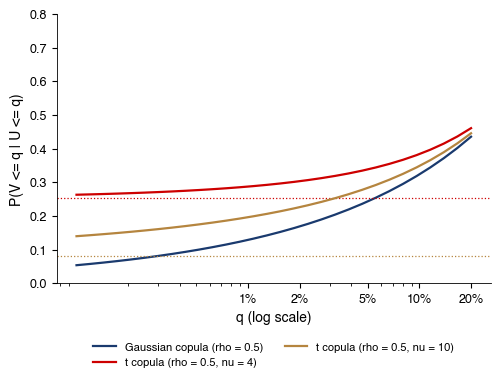

In [10]:
# Rezolvare
def joint_tail_prob(q, rho, nu=None):
    """P(U <= q, V <= q) for the Gaussian copula (nu=None) or the t copula (nu degrees of freedom), by deterministic
    one-dimensional quadrature: Y | X = x is Normal(rho x, 1 - rho^2), or
    t_{nu+1}(rho x, (nu + x^2)(1 - rho^2)/(nu + 1))."""
    if nu is None:
        a = stats.norm.ppf(q)
        f = lambda x: stats.norm.pdf(x) * stats.norm.cdf((a - rho * x) / np.sqrt(1 - rho ** 2))
    else:
        a = stats.t.ppf(q, nu)
        f = lambda x: stats.t.pdf(x, nu) * stats.t.cdf((a - rho * x) / np.sqrt((nu + x * x) * (1 - rho ** 2) / (nu + 1)), nu + 1)
    return integrate.quad(f, -np.inf, a, epsabs=1e-14, epsrel=1e-10, limit=200)[0]


def a_tail_gauss_t(rho=0.5, nus=(3, 4, 10, 30)):
    """A3: lambda of the t copula and the conditional probability P(V<=q | U<=q) at a finite level."""
    out = {}
    for nu in nus:
        arg = np.sqrt((nu + 1) * (1 - rho) / (1 + rho))
        out[nu] = dict(arg=arg, lam=2 * stats.t.cdf(-arg, nu + 1))
    qs = np.array([0.10, 0.05, 0.01, 0.001])
    gauss = np.array([joint_tail_prob(q, rho) / q for q in qs])
    t4 = np.array([joint_tail_prob(q, rho, 4) / q for q in qs])
    return out, qs, gauss, t4


def fig_tail_gauss_t(rho=0.5):
    qs = np.geomspace(0.001, 0.2, 30)
    g = [joint_tail_prob(q, rho) / q for q in qs]
    fig, ax = plt.subplots(figsize=(5.6, 3.5))
    ax.plot(qs, g, color=MainBlue, lw=1.6, label='Gaussian copula (rho = 0.5)')
    for nu, c in ((4, IDAred), (10, Amber)):
        ax.plot(qs, [joint_tail_prob(q, rho, nu) / q for q in qs], color=c, lw=1.6, label=f't copula (rho = 0.5, nu = {nu})')
        lam = 2 * stats.t.cdf(-np.sqrt((nu + 1) * (1 - rho) / (1 + rho)), nu + 1)
        ax.axhline(lam, color=c, ls=':', lw=0.9)
    ax.set_xscale('log')
    ax.set_xticks([0.01, 0.02, 0.05, 0.1, 0.2])
    ax.set_xticklabels(['1%', '2%', '5%', '10%', '20%'])
    ax.set_xlabel('q (log scale)')
    ax.set_ylabel('P(V <= q | U <= q)')
    ax.set_ylim(0, 0.8)
    legend_outside_bottom(ax, ncol=2, y=-0.18)
    save_fig('ch6_sem_tail_gauss_t')


lam, qs, gauss, t4 = a_tail_gauss_t()
print({nu: round(d['lam'], 4) for nu, d in lam.items()})
print(pd.DataFrame({'q': qs, 'Gaussian': gauss, 't4': t4}).round(4))
fig_tail_gauss_t()

### A4. Derivarea distorsiunii Forbes–Rigobon [Propus]

- **Exemplu de urmat**: [A1](https://danpele.github.io/MFM/RO/Seminarii/seminar6_dependenta_multivariata_ro.pdf#nameddest=ex-A1); **modelul**: $y_t=\alpha+\beta x_t+\varepsilon_t$ cu $\operatorname{Cov}(x_t,\varepsilon_t)=0$ presupusă; $\beta$ și $\sigma^2_\varepsilon$ egale în perioada calmă și în criză; se schimbă doar $\sigma^2_{x,c}=(1+\delta)\sigma^2_x$

- **Cerințe**

1.  Scrieți $\rho^2$ ca funcție de $k=\beta^2\sigma^2_x/\sigma^2_\varepsilon$, folosind $\operatorname{Cov}(x,y)$ și $\operatorname{Var}(y)$.

2.  Deduceți $\rho_c=\rho\sqrt{(1+\delta)/(1+\delta\rho^2)}$ și arătați că $|\rho_c|>|\rho|$ pentru $0<|\rho|<1$.

3.  Inversați relația pentru a obține $\rho^*=\rho_c/\sqrt{1+\delta(1-\rho_c^2)}$.

4.  Presupuneți că în criză crește și $\sigma^2_\varepsilon$, la $(1+\gamma)\sigma^2_\varepsilon$ cu $0<\gamma<\delta$: calculați corelația adevărată din criză și, luînd corelația calmă drept reper, precizați în ce direcție este atunci deplasat $\rho^*$.

- **Raportați**: fiecare pas cu o propoziție de justificare și răspunsul la cerința 4 cu o interpretare economică

[Exercițiul A4 în seminar](https://danpele.github.io/MFM/RO/Seminarii/seminar6_dependenta_multivariata_ro.pdf#nameddest=ex-A4)

In [11]:
# Codul vostru aici


### A5. Algebra DCC și un șoc [Propus]

- **Exemplu de urmat**: [B1](https://danpele.github.io/MFM/RO/Seminarii/seminar6_dependenta_multivariata_ro.pdf#nameddest=ex-B1); ținta $\bar Q=\begin{pmatrix}1&-0{,}248\\-0{,}248&1\end{pmatrix}$, $a=0{,}052232$, $b=0{,}933518$, $Q_{t-1}=\bar Q$, un șoc $\varepsilon_{t-1}=(-2{,}0,\,1{,}0)$; notație: $Q^*_t=\operatorname{diag}(Q_t)$, o matrice variabilă în timp, nu ținta fixă

- **Cerințe**

1.  Arătați prin inducție că $Q_t$ este pozitiv definită pentru orice $t$ cînd $Q_0=\bar Q$ este.

2.  Calculați $Q_t$ și $R_{t,12}$ după șoc și timpul de înjumătățire aproximativ $\ln0{,}5/\ln(a+b)$.

3.  Arătați că $\mathbb{E}[Q_t]=\bar Q$ cere $\mathbb{E}[R_t]=\bar Q$, fals în general; pentru DCC-ul corectat al lui [Aielli (2013)](https://doi.org/10.1080/07350015.2013.771027) ([[instrumente pentru extensii: modele dinamice]{style="color: MainBlue"}](https://danpele.github.io/MFM/RO/Seminarii/seminar6_dependenta_multivariata_ro.pdf#nameddest=sem6p27)), arătați că $\mathbb{E}[Q_t]=\bar Q^*$.

- **Raportați**: demonstrațiile, $R_{t,12}$ și timpul de înjumătățire; este acesta o regulă pentru frecvența reechilibrării unui hedge?

[Exercițiul A5 în seminar](https://danpele.github.io/MFM/RO/Seminarii/seminar6_dependenta_multivariata_ro.pdf#nameddest=ex-A5)

In [12]:
# Codul vostru aici


### A6. Corelațiile posibile [Propus]

- **Exemplu de urmat**: [A2](https://danpele.github.io/MFM/RO/Seminarii/seminar6_dependenta_multivariata_ro.pdf#nameddest=ex-A2); $X=e^{\sigma_1Z_1}$, $Y=e^{\sigma_2Z_2}$, $Z_i\sim N(0,1)$: variabile lognormale ipotetice, cu marginale fixate și dependență liberă

- **Instrumente**: marginile Fréchet--Hoeffding $W\le C\le M$ ([[copule și teorema lui Sklar]{style="color: MainBlue"}](https://danpele.github.io/MFM/RO/Seminarii/seminar6_dependenta_multivariata_ro.pdf#nameddest=sem6p3)); identitatea lui Hoeffding și $\mathbb{E}(e^{aZ})=e^{a^2/2}$ ([[instrumente pentru extensii: corelațiile posibile]{style="color: MainBlue"}](https://danpele.github.io/MFM/RO/Seminarii/seminar6_dependenta_multivariata_ro.pdf#nameddest=sem6p25))

- **Cerințe**

1.  Arătați că $\rho(X,Y)$ este maximă pentru $Z_2=Z_1$ și minimă pentru $Z_2=-Z_1$.

2.  Calculați pe rînd $\mathbb{E} X$, $\mathbb{E} Y$, $\mathbb{E} XY$, $\operatorname{Var} X$, $\operatorname{Var} Y$ și deduceți $\rho_{\max}$ și $\rho_{\min}$ în formă închisă.

3.  Calculați-le pentru $\sigma_1=1$, $\sigma_2=2$ și interpretați $\rho=0{,}3$ față de acest interval.

[Exercițiul A6 în seminar](https://danpele.github.io/MFM/RO/Seminarii/seminar6_dependenta_multivariata_ro.pdf#nameddest=ex-A6)

In [13]:
# Codul vostru aici


## Partea B — estimare și inferență

### B1. DCC pentru SPY și TLT [Rezolvat]

- GARCH(1,1) + DCC(1,1); raportul de verosimilitate față de Constant Conditional Correlation (model) (CCC); subperioadele 2002–2019 și 2020–2026; p-value-ul bootstrap a raportului de verosimilitate sub CCC; testul Wied–Krämer–Dehling pentru o schimbare a corelației lui $\varepsilon_t$ la o dată necunoscută; erori standard prin bootstrap doar pentru pasul 2 și pentru ambii pași.
- Interpretare:
  - este $a+b$ stabil?
  - de ce $\chi^2$ este doar orientativ?
  - ce înseamnă o schimbare a lui $\bar Q$?

In [14]:
# Rezolvare
def b_dcc_spy_tlt():
    """B1: DCC on the full sample and on two subperiods; LR against CCC; the change in the mean correlation of z."""
    R = joint_returns(['spy', 'tlt'])
    P, V, Z, ll = garch_all(R)
    full = dcc_fit(Z)
    sub = {}
    for lab, sl in (('pre', slice(None, '2019-12-31')), ('post', slice('2020-01-01', None))):
        Rs = R.loc[sl]
        Ps, Vs, Zs, _ = garch_all(Rs)
        sub[lab] = dcc_fit(Zs)
        sub[lab]['n'] = len(Zs)
    z0, z1 = Z.loc[:'2021-12-31'], Z.loc['2022-01-01':]
    r0, r1 = z0.corr().iloc[0, 1], z1.corr().iloc[0, 1]
    zt, _ = fisher_z_test(r1, len(z1), r0, len(z0))
    return dict(full=full, sub=sub, r0=r0, r1=r1, zt=zt, p2=2 * (1 - stats.norm.cdf(abs(zt))),
                lr=2 * (full['loglik'] - full['ccc_loglik']), n=len(Z), P=P)


b1 = b_dcc_spy_tlt()
print('full:', round(b1['full']['a'], 4), round(b1['full']['b'], 4), 'LR =', round(b1['lr'], 1))
for k in ('pre', 'post'):
    print(k, round(b1['sub'][k]['a'], 4), round(b1['sub'][k]['b'], 4), round(b1['sub'][k]['Qbar'][0, 1], 3))
print('corr of z before/after 2022:', round(b1['r0'], 3), round(b1['r1'], 3), 'Fisher z =', round(b1['zt'], 2))

full: 0.0522 0.9335 LR = 533.4
pre 0.0565 0.9199 -0.35
post 0.0341 0.9527 0.003
corr of z before/after 2022: -0.343 0.126 Fisher z = 14.92


In [15]:
# Rezolvare, B1 cerința 4 și B1 extins (1), (3): testul de ruptură cu dată necunoscută, erorile standard în doi pași și testul CCC (199 de replicări, cîteva minute)
def wkd_test(x, y):
    """Q_T = max_j (j / sqrt(T)) |rho_j - rho_T| / D, D^2 = long-run variance of the correlation by the delta method,
    Bartlett kernel with bandwidth floor(T^(1/4)) (Wied, Kramer & Dehling, 2012). Under H0: sup |Brownian bridge|."""
    x, y = np.asarray(x, float), np.asarray(y, float)
    T = len(x)
    M = np.column_stack([x, y, x * x, y * y, x * y])
    r, g = corr_grad(M.mean(0))
    D = np.sqrt(g @ bartlett_lrv(M, int(np.floor(T ** 0.25))) @ g)
    C = np.cumsum(M, axis=0) / np.arange(1, T + 1)[:, None]
    m1, m2, m3, m4, m5 = C.T
    with np.errstate(invalid='ignore', divide='ignore'):
        rj = (m5 - m1 * m2) / np.sqrt((m3 - m1 ** 2) * (m4 - m2 ** 2))
    path = np.arange(1, T + 1) / np.sqrt(T) * np.abs(rj - r) / D
    path[:1] = 0
    j = int(np.nanargmax(path))
    Q = path[j]
    return dict(Q=Q, p=stats.kstwobign.sf(Q), j=j, path=path, D=D, rho=r)


def two_step_bootstrap(B=199):
    """Parametric residual bootstrap for (a, b): (i) step 2 only (DCC re-estimated on the simulated residuals),
    (ii) both steps (simulated GARCH returns, GARCH re-estimated, then DCC). The same innovations in (i) and (ii)."""
    R = joint_returns(['spy', 'tlt'])
    P, V, Z, _ = garch_all(R)
    d = dcc_fit(Z)
    X = Z.values
    L = np.linalg.cholesky(d['R'])
    eta = np.linalg.solve(L, X[:, :, None])[:, :, 0]
    eta = (eta - eta.mean(0)) / eta.std(0)
    rng = np.random.default_rng(SEED)
    one, two = [], []
    for _ in range(B):
        eps = simulate_dcc2(d['a'], d['b'], d['Qbar'], eta[rng.integers(0, len(eta), len(eta))])
        d1 = dcc_fit(pd.DataFrame(eps))
        one.append((d1['a'], d1['b']))
        sim = {c: simulate_garch(P.loc['mu', c], P.loc['omega', c], P.loc['alpha[1]', c], P.loc['beta[1]', c], eps[:, k])
               for k, c in enumerate(R.columns)}
        Rs = pd.DataFrame(sim, index=R.index) / 100
        _, _, Zs, _ = garch_all(Rs)
        d2 = dcc_fit(Zs)
        two.append((d2['a'], d2['b']))
    one, two = np.array(one), np.array(two)
    N.update(ts_a=d['a'], ts_b=d['b'], ts_se_a_hess=d['se_a'], ts_se_b_hess=d['se_b'],
             ts_se_a_one=one[:, 0].std(ddof=1), ts_se_b_one=one[:, 1].std(ddof=1),
             ts_se_a_two=two[:, 0].std(ddof=1), ts_se_b_two=two[:, 1].std(ddof=1),
             ts_se_ab_one=one.sum(1).std(ddof=1), ts_se_ab_two=two.sum(1).std(ddof=1),
             ts_mean_a_two=two[:, 0].mean(), ts_mean_b_two=two[:, 1].mean(), ts_B=B)
    return one, two


def ccc_null_bootstrap(names, tag, B=199):
    """p-value of the DCC-against-CCC statistic under H0: CCC. Constant-correlation innovations from the resampled
    decorrelated residuals, GARCH(1,1) returns simulated with the estimated parameters, then BOTH steps re-estimated on each path
    (univariate GARCH, target Qbar, (a, b)); the observed statistic is computed with the same procedure."""
    R = joint_returns(names)
    P, V, Z, _ = garch_all(R)
    d = dcc_fit(Z)
    lr_obs = 2 * (d['loglik'] - d['ccc_loglik'])
    X = Z.values
    Qbar = np.cov(X.T, bias=True)
    C = Qbar / np.sqrt(np.outer(np.diag(Qbar), np.diag(Qbar)))
    eta = np.linalg.solve(np.linalg.cholesky(C), X.T).T
    eta = (eta - eta.mean(0)) / eta.std(0)
    rng = np.random.default_rng(SEED)
    lrs = []
    for _ in range(B):
        eps = simulate_dcc2(0.0, 0.0, C, eta[rng.integers(0, len(eta), len(eta))])
        sim = {c: simulate_garch(P.loc['mu', c], P.loc['omega', c], P.loc['alpha[1]', c], P.loc['beta[1]', c], eps[:, k])
               for k, c in enumerate(R.columns)}
        _, _, Zs, _ = garch_all(pd.DataFrame(sim, index=R.index) / 100)
        ds = dcc_fit(Zs)
        lrs.append(2 * (ds['loglik'] - ds['ccc_loglik']))
    lrs = np.array(lrs)
    N.update({f'{tag}_lr_obs': lr_obs, f'{tag}_lr_null_q95': np.percentile(lrs, 95), f'{tag}_lr_null_max': lrs.max(),
              f'{tag}_lr_p_boot': (1 + np.sum(lrs >= lr_obs)) / (B + 1), f'{tag}_lr_B': B})


R = joint_returns(['spy', 'tlt'])
P, V, Z, _ = garch_all(R)
w = wkd_test(Z['spy'], Z['tlt'])
print('Q =', round(w['Q'], 3), 'p =', w['p'], 'break:', Z.index[w['j']].date())
one, two = two_step_bootstrap()
print('se step 2 only', one.std(0, ddof=1).round(4), 'se both steps', two.std(0, ddof=1).round(4))
ccc_null_bootstrap(['spy', 'tlt'], 'cccb')   # B1, cerința 4: LR față de CCC, p-valoarea bootstrap sub CCC
print({k: round(v, 3) for k, v in N.items() if k.startswith('cccb')})

Q = 4.245 p = 4.45205767928961e-16 break: 2020-08-03


se step 2 only [0.0051 0.0077] se both steps [0.0052 0.0077]


{'cccb_lr_obs': np.float64(533.429), 'cccb_lr_null_q95': np.float64(6.643), 'cccb_lr_null_max': np.float64(15.727), 'cccb_lr_p_boot': np.float64(0.005), 'cccb_lr_B': 199}


### B2. Copula Gaussiană față de copula t pentru S&P 500 și Euro Stoxx 50 [Rezolvat]

- Verosimilitate maximă canonică, Akaike Information Criterion (AIC), raport de verosimilitate bootstrap pentru $\nu=\infty$, adecvare Rosenblatt (cîte 499 de replicări bootstrap), intervale bootstrap pentru $\nu$ și $\lambda$, erori standard sandwich (B2 și B2 extins; celula rulează circa 15 minute).
- Interpretare:
  - de ce nu $\chi^2_1$?
  - dovedește nerespingerea testului de adecvare că modelul este corect?

In [16]:
# Rezolvare
def b_gauss_vs_t(W, U, B=200, B_test=499):
    """B2: Gaussian vs t for S&P 500 / Euro Stoxx 50 weekly: ML, LR for nu, goodness of fit, bootstrap CI for lambda.
    The tests (goodness of fit and LR) use B_test = 499 replications, so the smallest possible p-value is 1/500 = 0.002."""
    u, v = U[:, 0], U[:, 1]
    fg, ft = fit_copula('gaussian', u, v), fit_copula('t', u, v)
    gg = gof_test('gaussian', u, v, B=B_test, seed=SEED, fit=fg)
    gt = gof_test('t', u, v, B=B_test, seed=SEED, fit=ft)
    lr = 2 * (ft['loglik'] - fg['loglik'])
    rng = np.random.default_rng(SEED)
    lam_b, nu_b = [], []
    for _ in range(B):
        X = pseudo_obs(simulate('t', ft['par'], len(u), rng))
        fb = fit_copula('t', X[:, 0], X[:, 1])
        lam_b.append(fb['lamL'])
        nu_b.append(fb['par'][1])
    lam_b, nu_b = np.array(lam_b), np.array(nu_b)
    # p-value of the LR by a parametric bootstrap under H0 (Gaussian copula), because nu = infinity is on the boundary
    lr_b = []
    for _ in range(B_test):
        X = pseudo_obs(simulate('gaussian', fg['par'], len(u), rng))
        lr_b.append(2 * (fit_copula('t', X[:, 0], X[:, 1])['loglik'] - fit_copula('gaussian', X[:, 0], X[:, 1])['loglik']))
    lr_b = np.array(lr_b)
    return dict(fg=fg, ft=ft, gg=gg, gt=gt, lr=lr, lr_p_boot=(1 + np.sum(lr_b >= lr)) / (len(lr_b) + 1),
                lr_p_chi2half=0.5 * (1 - stats.chi2.cdf(lr, 1)), lam_ci=np.percentile(lam_b, [5, 95]),
                nu_ci=np.percentile(nu_b, [5, 95]), emp=[empirical_tail_dep(u, v, q) for q in (0.05, 0.10)],
                lr_b=lr_b, lam_b=lam_b, nu_b=nu_b)


b2 = b_gauss_vs_t(W2, U2)
print('Gaussian:', b2['fg'])
print('t:', b2['ft'])
print('LR =', round(b2['lr'], 1), 'bootstrap p =', round(b2['lr_p_boot'], 4))
print('fit p: Gaussian', b2['gg']['p'], 't', b2['gt']['p'])
print('nu CI', b2['nu_ci'].round(2), 'lambda CI', b2['lam_ci'].round(3))
for fam, f in (('gaussian', b2['fg']), ('t', b2['ft'])):
    print(fam, 'se inverse Hessian, sandwich:', [x.round(4) for x in cml_se(fam, f['par'], U2[:, 0], U2[:, 1])])

Gaussian: {'family': 'gaussian', 'par': [0.7707785800505685], 'loglik': 623.3069873766287, 'aic': -1244.6139747532575, 'bic': -1239.3747597794777, 'tau_model': 0.5602650692201933, 'lamL': 0.0, 'lamU': 0.0}
t: {'family': 't', 'par': [0.7750279084815949, 3.9056474800351237], 'loglik': 674.2149814678905, 'aic': -1344.429962935781, 'bic': -1333.9515329882215, 'tau_model': 0.5645284769054757, 'lamL': 0.46677193837314634, 'lamU': 0.46677193837314634}
LR = 101.8 bootstrap p = 0.002
fit p: Gaussian 0.002 t 0.874
nu CI [2.98 4.77] lambda CI [0.423 0.518]
gaussian se inverse Hessian, sandwich: [array([0.0086]), array([0.0138])]
t se inverse Hessian, sandwich: [array([0.0115, 0.5589]), array([0.0131, 0.5792])]


### B3. Contagiunea în 2008 și 2020 [Propus]

- **Întrebările**

  - s-au întărit legăturile dintre S&P 500 și Euro Stoxx 50 sau BET în cele două crize?

  - rămîn ele mai puternice după luarea în calcul a volatilității mai mari din Statele Unite ale Americii (SUA)?

- **Date**: randamente logaritmice pe 2 zile $\ln P_t-\ln P_{t-2}$ ($P_t$: nivelul de închidere din ziua $t$) în zilele comune de tranzacționare; S&P 500 este sursa; un randament este atribuit ferestrei care conține data lui finală

                                             calm                       criză
  ------------------------------------------ -------------------------- --------------------------
  2008                                       14.09.2007 -- 12.09.2008   15.09.2008 -- 31.03.2009
  2020                                       19.02.2019 -- 19.02.2020   20.02.2020 -- 30.04.2020
  2008: $n$ (pe 2 zile)   242                        130
  2020: $n$ (pe 2 zile)   241                        47

- **Exemplu de urmat**: [A1](https://danpele.github.io/MFM/RO/Seminarii/seminar6_dependenta_multivariata_ro.pdf#nameddest=ex-A1); **Cerințe la seminar**

1.  Rezolvați complet cazul BET în 2008: calculați $\rho_{calm}$, $\rho_c$, $\delta$ și $\rho^*$, apoi repetați pentru celelalte trei cazuri.

2.  Ca termen de comparație istoric, aplicați testele Fisher $z$ unilaterale ([[compararea a două corelații: testul Fisher z]{style="color: MainBlue"}](https://danpele.github.io/MFM/RO/Seminarii/seminar6_dependenta_multivariata_ro.pdf#nameddest=sem6p22)) pentru $H_0:\rho_c\le\rho_{calm}$ și $H_0:\rho^*\le\rho_{calm}$, cu $n$ partea întreagă a jumătății numărului de randamente suprapuse pe 2 zile, o corecție euristică. Criza din 2020 are doar 23 de perechi efective după această regulă: Fisher este orientativ; comparați cu bootstrap-ul.

- **Raportați**: un tabel pe crize și piețe ($\delta$, $\rho_{calm}$, $\rho_c$, $p_{brut}$, $\rho^*$, $p_{corectat}$); notebook: secțiunea [B3](https://danpele.github.io/MFM/RO/Seminarii/seminar6_dependenta_multivariata_ro.pdf#nameddest=ex-B3)

- **Interpretare**

  - de ce este $\delta$ mult mai mare în 2020?

  - ce ipoteză este cea mai puțin credibilă pentru o pandemie?

- Cerințele 3--4 (bootstrap cu $\delta$ estimat, ferestre mai scurte) vin după curs, în secțiunea de temă

- **Exemplu de urmat**: [A1](https://danpele.github.io/MFM/RO/Seminarii/seminar6_dependenta_multivariata_ro.pdf#nameddest=ex-A1) și tabelul [B3](https://danpele.github.io/MFM/RO/Seminarii/seminar6_dependenta_multivariata_ro.pdf#nameddest=ex-B3) de la seminar; **Cerințe**

3.  Testați $D=\rho^*-\rho_{calm}$ prin bootstrap, cu $\delta$ estimat la fiecare extragere:

    - reeșantionați vectorii comuni (S&P 500, ținta) în interiorul fiecărei ferestre cu un bootstrap staționar [Politis & Romano (1994)](https://doi.org/10.1080/01621459.1994.10476870), bloc mediu de 10 zile, 1 999 de extrageri;

    - recalculați $\hat\delta$, $\rho^*$ și $\rho_{calm}$; raportați intervalul de 90% al lui $D$ și $p=$ proporția extragerilor cu $D\le0$.

4.  Sensibilitate: încheiați ferestrele de criză pe 31 decembrie 2008 și pe 31 martie 2020.

- **Raportați**: tabelul de la seminar cu o coloană pentru intervalul de 90% al lui $D$ și un grafic; notebook: secțiunea [B3](https://danpele.github.io/MFM/RO/Seminarii/seminar6_dependenta_multivariata_ro.pdf#nameddest=ex-B3), celula de bootstrap

- **Interpretare**: modifică estimarea lui $\delta$ vreo concluzie de la cerința 2?

[Exercițiul B3 în seminar](https://danpele.github.io/MFM/RO/Seminarii/seminar6_dependenta_multivariata_ro.pdf#nameddest=ex-B3)

In [17]:
# Codul vostru aici


**Cerințele 3–4, după curs**: bootstrap-ul lui $D=\rho^*-\rho_{calm}$, cu $\delta$ estimat la fiecare extragere.

### B4. Clayton față de Gumbel pentru pierderile simultane BET și Euro Stoxx 50 [Propus]

- **Exemplu de urmat**: [B2](https://danpele.github.io/MFM/RO/Seminarii/seminar6_dependenta_multivariata_ro.pdf#nameddest=ex-B2) și [A2](https://danpele.github.io/MFM/RO/Seminarii/seminar6_dependenta_multivariata_ro.pdf#nameddest=ex-A2); **date**: închideri zilnice BET și Euro Stoxx 50 din 5 ianuarie 2010, aliniate pe zilele comune (închideri aproape sincrone), $T=4\,154$; notebook: secțiunea [B4](https://danpele.github.io/MFM/RO/Seminarii/seminar6_dependenta_multivariata_ro.pdf#nameddest=ex-B4)

- Filtrați fiecare serie cu GARCH(1,1) cu medie constantă, Quasi-Maximum Likelihood (QML) Gaussian ca în [B1](https://danpele.github.io/MFM/RO/Seminarii/seminar6_dependenta_multivariata_ro.pdf#nameddest=ex-B1); pierderile $L=-\varepsilon$ (minus randamentele standardizate) și pseudo-observațiile lor: crahurile simultane se află în *upper tail*

- **Cerințe**

1.  Înainte de estimare: ce familie credeți că își plasează dependența în cozi acolo unde se află crahurile simultane, Clayton sau Gumbel pe pierderi?

2.  Estimați Clayton și Gumbel prin Canonical Maximum Likelihood (CML) (copulele Gaussiană și t ca repere); raportați AIC, $\lambda_L$, $\lambda_U$ și $p$ de adecvare Rosenblatt (200 de extrageri; 100 pentru t).

3.  Calculați probabilitățile empirice din cele două cozi la $q=5\%$ și $10\%$ și comparați-le cu curbele estimate.

4.  Explicați ce reprezintă copula Clayton rotită cu $180^\circ$ (de supraviețuire) pe pierderi.

[Exercițiul B4 în seminar](https://danpele.github.io/MFM/RO/Seminarii/seminar6_dependenta_multivariata_ro.pdf#nameddest=ex-B4)

In [18]:
# Codul vostru aici


### B5. Bitcoin și S&P 500: DCC cu benzi bootstrap [Propus]

- **Exemplu de urmat**: [B1](https://danpele.github.io/MFM/RO/Seminarii/seminar6_dependenta_multivariata_ro.pdf#nameddest=ex-B1); **date**: Bitcoin (în United States dollar (USD)) și indicele S&P 500 (indicele, nu SPY: rezultatul cu SPY din curs este un reper separat), zilele comune de tranzacționare din 18 septembrie 2014, $T=3\,018$; mișcările Bitcoin din weekend intră în randamentul de luni

- **Cerințe**

1.  Estimați GARCH(1,1) cu medie constantă prin Gaussian QML și DCC(1,1); calculați corelația condiționată medie înainte și după 1 ianuarie 2020.

2.  Evaluați prin bootstrap incertitudinea parametrilor, 200 de extrageri:

    - păstrați fixate reziduurile GARCH și ținta $\bar Q$; decorelați $\eta_t=L_t^{-1}\varepsilon_t$ ([[instrumente pentru extensii: modele dinamice]{style="color: MainBlue"}](https://danpele.github.io/MFM/RO/Seminarii/seminar6_dependenta_multivariata_ro.pdf#nameddest=sem6p27)); reeșantionați împreună $\eta_t$;

    - simulați un DCC cu $(\hat a,\hat b)$, reestimați $(a,b)$, apoi refiltrați reziduurile *observate* cu fiecare $(a,b)$ bootstrap.

3.  Trasați banda punctuală de 90% pentru $\rho_t$ și un interval de 90% pentru schimbarea corelației medii după 2020.

- **Interpretare**

  - ce incertitudine ignoră banda?

  - de ce nu este un interval de prognoză?

[Exercițiul B5 în seminar](https://danpele.github.io/MFM/RO/Seminarii/seminar6_dependenta_multivariata_ro.pdf#nameddest=ex-B5)

In [19]:
# Codul vostru aici


### B6. O copulă t dinamică pentru S&P 500 și Euro Stoxx 50 [Propus]

- **Exemplu de urmat**: [B2](https://danpele.github.io/MFM/RO/Seminarii/seminar6_dependenta_multivariata_ro.pdf#nameddest=ex-B2) și copula t dinamică din curs; date: pseudo-observațiile săptămînale din [A2](https://danpele.github.io/MFM/RO/Seminarii/seminar6_dependenta_multivariata_ro.pdf#nameddest=ex-A2) ($n=1\,393$); reper: copula t statică din [B2](https://danpele.github.io/MFM/RO/Seminarii/seminar6_dependenta_multivariata_ro.pdf#nameddest=ex-B2)

- Rangurile săptămînale nu sînt filtrate GARCH: corelația dinamică poate absorbi și regimuri comune de volatilitate. Comparați cu reziduuri filtrate înainte de a o interpreta drept schimbare a dependenței.

- Copula t Generalised Autoregressive Score (model) (GAS) ([Creal, Koopman & Lucas (2013)](https://doi.org/10.1002/jae.1279), scalare unitară) din [[instrumente pentru extensii: modele dinamice]{style="color: MainBlue"}](https://danpele.github.io/MFM/RO/Seminarii/seminar6_dependenta_multivariata_ro.pdf#nameddest=sem6p27), pornită din $f_1=\omega/(1-\beta_{GAS})$; cu $x,y$ cuantilele $t_\nu$ și $Q=x^2+y^2-2\rho xy$: $\ln c=\text{const}-\frac12\ln(1-\rho^2)-\frac{\nu+2}2\ln\big(1+\frac{Q}{\nu(1-\rho^2)}\big)+\frac{\nu+1}2\sum\ln(1+x^2/\nu)$

- **Cerințe**

1.  Deduceți $s_t=(1-\rho_t^2)\,\partial\ln c/\partial\rho$ prin derivarea funcției compuse și verificați-l numeric cu o diferență finită.

2.  Estimați $(\omega,A,\beta_{GAS},\nu)$ cu $0\le A\le1$, $0\le\beta_{GAS}<1$, $\nu>2$, pornind de la estimarea statică.

3.  Calculați Likelihood Ratio (test) (LR) față de copula t statică și p-value-ul lui printr-un bootstrap sub copula statică ($B_{boot}=199$, simulare, ranguri noi, reestimarea ambelor); reprezentați $\rho_t$ față de $\rho$ static.

[Exercițiul B6 în seminar](https://danpele.github.io/MFM/RO/Seminarii/seminar6_dependenta_multivariata_ro.pdf#nameddest=ex-B6)

In [20]:
# Codul vostru aici


## Partea C — critica unui răspuns AI, întrebare deschisă și temă de proiect

### C1. Critica unui răspuns AI [Propus]

- **Exemplu de urmat**: [A2](https://danpele.github.io/MFM/RO/Seminarii/seminar6_dependenta_multivariata_ro.pdf#nameddest=ex-A2) și [A3](https://danpele.github.io/MFM/RO/Seminarii/seminar6_dependenta_multivariata_ro.pdf#nameddest=ex-A3) \[Rezolvat\]; **date**: codul de mai sus cu $\hat\tau=0{,}50$ și $\nu=4$; pentru verificarea pe date, reziduurile JPM--BAC din notebook (secțiunea [C1](https://danpele.github.io/MFM/RO/Seminarii/seminar6_dependenta_multivariata_ro.pdf#nameddest=ex-C1))

- Răspunsul conține **trei** greșeli tipice pentru lucrul cu copule; restul este corect

- **Cerințe**

1.  Găsiți cele trei linii greșite și explicați într-o propoziție de ce este greșită fiecare.

2.  Pentru fiecare, indicați dovada care o evidențiază: o formulă din [A2](https://danpele.github.io/MFM/RO/Seminarii/seminar6_dependenta_multivariata_ro.pdf#nameddest=ex-A2) sau [A3](https://danpele.github.io/MFM/RO/Seminarii/seminar6_dependenta_multivariata_ro.pdf#nameddest=ex-A3), o verificare a celei mai mari pseudo-observații sau o mică simulare.

3.  Scrieți cele trei linii corectate și recalculați $\rho$ și $\lambda$ pentru $\hat\tau=0{,}50$, $\nu=4$.

4.  Precizați care erori modifică $\lambda$ afișat și care afectează doar datele de intrare ale verosimilității.

- **Raportați**: un tabel cu trei rînduri (eroare, dovadă, corecție) și $\rho$ și $\lambda$ corectate; notați în `AI_ERRORS.md` erorile găsite efectiv

[Exercițiul C1 în seminar](https://danpele.github.io/MFM/RO/Seminarii/seminar6_dependenta_multivariata_ro.pdf#nameddest=ex-C1)

In [21]:
Rb, Zb, Ub = bank_copula_data()
e = Zb.rename(columns={'jpm': 'JPM', 'bac': 'BAC'})
# răspunsul asistentului, nemodificat
tau = stats.kendalltau(e['JPM'], e['BAC'])[0]       # Kendall's tau
rho = 2 * np.sin(np.pi * tau / 6)                  # copula correlation
u = e.rank() / len(e)                              # pseudo-observations
z = stats.t.ppf(u, df=4)                           # input of the t-copula likelihood
nu = 4
x = np.sqrt((nu + 1) * (1 - rho) / (1 + rho))
lam = 2 * stats.t.cdf(-x, df=nu)                   # tail dependence
print('tau', round(tau, 3), 'rho', round(rho, 3), 'lambda', round(lam, 3), 'infinite z', int(np.isinf(z).sum()))

tau 0.641 rho 0.659 lambda 0.368 infinite z 2


In [22]:
# Codul vostru aici


### C2. Integrarea pieței de acțiuni din România cu zona euro după 2020 [Propus]

- **Exemplu de urmat**: [A1](https://danpele.github.io/MFM/RO/Seminarii/seminar6_dependenta_multivariata_ro.pdf#nameddest=ex-A1), [B1](https://danpele.github.io/MFM/RO/Seminarii/seminar6_dependenta_multivariata_ro.pdf#nameddest=ex-B1); **date**: randamente săptămînale BET și Euro Stoxx 50 în zilele comune, 2010--2019 ($n=520$) față de 2020--2026 ($n=351$); notebook: secțiunea [C2](https://danpele.github.io/MFM/RO/Seminarii/seminar6_dependenta_multivariata_ro.pdf#nameddest=ex-C2)

- 2020 a adus coronavirus disease 2019 (COVID-19) și trecerea României la statutul Secondary Emerging la Financial Times Stock Exchange (FTSE Russell, index provider) (FTSE) Russell ([FTSE Russell (2019)](https://www.lseg.com/en/media-centre/press-releases/ftse-russell/2019/ftse-russell-announces-results-country-classification-review-equities-and-fixed-income)): o comparație descriptivă între perioade, nu un test cauzal al trecerii

- **Cerințe**

1.  Estimați schimbarea corelației săptămînale cu un interval bootstrap staționar de 95% ([Politis & Romano (1994)](https://doi.org/10.1080/01621459.1994.10476870), reeșantionare în fiecare perioadă, bloc mediu de 8 săptămîni, 2 000 de extrageri) și $p$ unilateral pentru $H_0$: nicio creștere, proporția extragerilor $\le0$.

2.  Efectuați două verificări separate față de aceeași referință: corecția Forbes--Rigobon pentru schimbarea volatilității Euro Stoxx 50 și corelația fără 20 februarie -- 30 aprilie 2020.

3.  Opțional: $\tau$ Kendall, beta $\operatorname{Cov}(\text{BET},\text{Stoxx})/\operatorname{Var}(\text{Stoxx})$, probabilitatea din lower tail la $q=10\%$ și un DCC săptămînal.

- Context din curs: corelații mobile pe 104 săptămîni

- **Raportați**: un tabel cu toate măsurile în ambele perioade și o concluzie și limitele ei

[Exercițiul C2 în seminar](https://danpele.github.io/MFM/RO/Seminarii/seminar6_dependenta_multivariata_ro.pdf#nameddest=ex-C2)

In [23]:
# Codul vostru aici


### C3. Volatilitatea comună globală, temă de proiect [Propus]

- **Exemplu de urmat**: [B1](https://danpele.github.io/MFM/RO/Seminarii/seminar6_dependenta_multivariata_ro.pdf#nameddest=ex-B1), [C2](https://danpele.github.io/MFM/RO/Seminarii/seminar6_dependenta_multivariata_ro.pdf#nameddest=ex-C2) și studiul de caz din curs ([Engle & Campos-Martins (2023)](https://doi.org/10.1016/j.jfineco.2022.09.009)); modelul COmmon VOLatility (global COVOL: the size of the volatility shock common to all assets) (COVOL) din [[instrumente pentru extensii: modele dinamice]{style="color: MainBlue"}](https://danpele.github.io/MFM/RO/Seminarii/seminar6_dependenta_multivariata_ro.pdf#nameddest=sem6p27), $x_t$ pătratul COVOL global

- **Date**: prețurile de închidere ajustate ale celor 20 de ETF-uri listate în SUA din datele de piață ale cursului (11 ETF-uri sectoriale; Russell 1000 Growth și Value; Russell 2000; piețe dezvoltate și emergente din afara SUA; aur; obligațiuni de stat pe termen lung; obligațiuni corporative; petrol): XLB, XLC, XLE, XLF, XLI, XLK, XLP, XLRE, XLU, XLV, XLY, IWF, IWD, IWM, EFA, EEM, GLD, TLT, iShares iBoxx Investment Grade Corporate Bond ETF (LQD), United States Oil Fund (ETF ticker) (USO), fiecare de la prima zi pînă la 18 septembrie 2026 (panel neechilibrat); indicele Cboe Volatility Index (VIX), închideri zilnice

- **Cerințe**

1.  Filtrare: randamente logaritmice zilnice; medie autoregresivă autoregressive model (AR)(1), cu prima componentă principală (first principal component (PC1), Principal Component 1) a randamentelor ca factor (precizați cum formați PC1 pe panelul neechilibrat); GARCH(1,1); păstrați reziduurile standardizate ale ETF-urilor și ale PC1.

2.  Încărcări egale: $\hat x_t=\frac1N\sum_ie_{it}^2$ pe seriile observate în acea zi; listați cele mai mari 20 de zile înainte și după 1 martie 2021, cu randamentul mediu și eticheta evenimentului.

3.  Comparați corelația medie a reziduurilor cu cea a pătratelor lor; apoi, ca proiect de echipă, estimați încărcări diferite prin algoritmul alternant (iterativ) (Secțiunea 5.3 a articolului), testul $\xi$ și regresia VIX.

- **Raportați**: cele două tabele cu primele 20 de zile, comparația corelațiilor și, pentru proiect, încărcările, $\xi$ și regresia cu erori standard; interpretare: de ce poate o zi cu randament mediu pozitiv să ocupe o poziție înaltă în clasament?

[Exercițiul C3 în seminar](https://danpele.github.io/MFM/RO/Seminarii/seminar6_dependenta_multivariata_ro.pdf#nameddest=ex-C3)

In [24]:
def covol_panel():
    """Unbalanced panel of daily log returns (each ETF on its own calendar, from its first day)
    and the PC1 factor (Section 9): the least-squares score on the first principal component of the
    correlation matrix of the returns, computed each day from the ETFs available."""
    R = pd.concat([np.log(load_price('etf_' + e.lower())).diff().rename(e) for e in COVOL_ETFS], axis=1)
    R = R.loc['2000-01-01':].dropna(how='all')
    Zs = (R - R.mean()) / R.std()
    w_val, w_vec = np.linalg.eigh(Zs.corr().values)
    w = w_vec[:, -1] * np.sign(w_vec[:, -1].sum())
    avail = Zs.notna().values
    f = np.nansum(Zs.values * w, axis=1) / (avail * w ** 2).sum(axis=1)
    return R, pd.Series(f, index=R.index, name='PC1')


def covol_residuals(R, f):
    """AR(1) with the PC1 factor in the mean and GARCH(1,1) for each ETF; AR(1)-GARCH(1,1) for PC1.
    Returns the standardised residuals (unbalanced panel)."""
    E = {}
    for c in R.columns:
        r = 100 * R[c].dropna()
        x = f.reindex(r.index).to_frame()
        res = arch_model(r, x=x, mean='ARX', lags=1, vol='GARCH', p=1, q=1).fit(disp='off')
        E[c] = res.resid / res.conditional_volatility
    res = arch_model(f, mean='AR', lags=1, vol='GARCH', p=1, q=1).fit(disp='off')
    E['PC1'] = res.resid / res.conditional_volatility
    return pd.DataFrame(E).dropna(how='all')


R_etf, pc1 = covol_panel()
E = covol_residuals(R_etf, pc1)
print(E.shape, E.index[0].date(), E.index[-1].date())

(6717, 21) 2000-01-04 2026-09-18


In [25]:
# Codul vostru aici


### B1ext. Incertitudinea corelației și EWMA [Propus]

- Date: aceleași randamente log zilnice din prețuri ajustate SPY--TLT ca în [B1](https://danpele.github.io/MFM/RO/Seminarii/seminar6_dependenta_multivariata_ro.pdf#nameddest=ex-B1), restrînse la 2002--2021; aliniați prețurile înainte de diferențiere.

- Calculați corelația și trei erori standard: Fisher, metoda delta cu $L=0$ și Heteroskedasticity and Autocorrelation Consistent (standard errors) (HAC) Bartlett cu $L=\lfloor4(T/100)^{2/9}\rfloor$. Derivarea prin vectorul de momente este în [curs, incertitudinea corelației](../Cursuri/capitol6_dependenta_multivariata.pdf).

- Replicați reperele cursului: erori standard de aproximativ $0{,}0120$, $0{,}0217$, $0{,}0227$. Raportați mărimea eșantionului, lagul și raportul HAC/Fisher.

- Calculați traiectoria corelației EWMA cu decay $0{,}94$: inițializați covarianța din primele 100 de randamente, apoi prognozați fiecare zi folosind numai randamentul precedent. Comparați cu o corelație mobilă pe 252 de zile.

- Predați tabelul celor trei erori și graficul celor două traiectorii. Explicați de ce o eroare mai mare schimbă forța inferenței fără să schimbe corelația estimată pe întregul eșantion.

- Verificări în cod: `corr_delta_se` din `inference_ch6.py`; `ewma_corr` din `dep_tools.py`, în [directorul capitolului](https://github.com/danpele/MFM/tree/main/Quantlets/Ch_06).

[Exercițiul de bază B1 în seminar](https://danpele.github.io/MFM/RO/Seminarii/seminar6_dependenta_multivariata_ro.pdf#nameddest=ex-B1)

In [ ]:
# Your code here
